# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Tangaran, Grisby Paul James
- _Student No._: 2024-02777
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Synthetic Data Interpolation](8-sininterp.png)

**Figure 1. Synthetic data interpolation.** Comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations

![Real-world data reconstruction](8-dowjones.png)

**Figure 2. Real-world data reconstruction.** Four reconstruction plots of the Dow Jones time-series dataset for sampling levels of 50%, 30%, 10%, and 5%

### Report discussion

**Interpolator comparison:** For the synthetic sine wave, quadratic and cubic interpolations most accurately reproduce the underlying smooth function, closely matching with the true curve. Linear interpolation creates angular, sharp transitions, while the nearest method produces a discontinuous, stepped approximation.

**Sampling-level comparison:** In the Dow Jones dataset, high sampling fractions (50% and 30%) allow all methods to reconstruct the original series accurately. However, as the sampling drops to 10% and 5%, reconstruction quality severely degrades. Higher-order methods (cubic and quadratic) overcompensate between sparse data points, creating unnatural distortions such as severe overshooting, undershooting, and exaggerated oscillations. Linear interpolation remains more stable at 5% sampling but loses all high-frequency details. A critical limitation across all methods is their inability to extrapolate; they are strictly confined to the sampled domain and cannot reliably predict values outside the established boundary points.

### Other comments
- none

---
## Section 2: Code

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

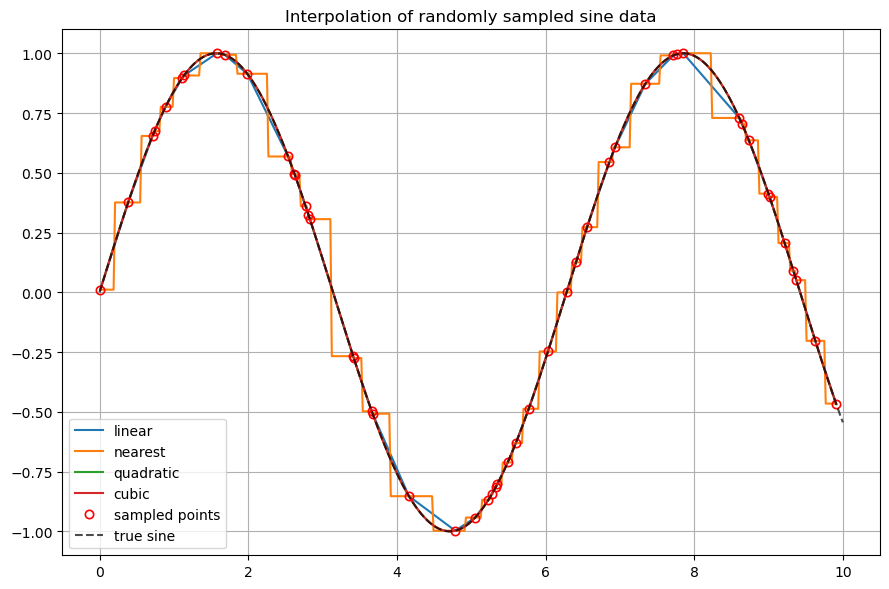

In [34]:
# Generate sine wave across full domain
x_true = np.linspace(0, 10, 500)
y_true = np.sin(x_true)

# Sample 50 random points from sine curve and sort x-coordinates
x_sample = np.sort(rng.uniform(0, 10, 50))
y_sample = np.sin(x_sample)

# Create evaluation domain strictly bounded within sorted sample endpoints
x_interp = np.linspace(x_sample[0], x_sample[-1], 500)

plt.figure(figsize=(9, 6))

# Construct and plot interpolation curves for each interpolation method
for method in ['linear', 'nearest', 'quadratic', 'cubic']:
    f = interpolate.interp1d(x_sample, y_sample, kind=method)
    plt.plot(x_interp, f(x_interp), label=method)

# Overlay discrete sample points and true underlying sine wave
plt.plot(x_sample, y_sample, 'o', color='red', fillstyle='none', markeredgewidth=1.2, label='sampled points')
plt.plot(x_true, y_true, 'k--', alpha=0.7, label='true sine')

plt.title('Interpolation of randomly sampled sine data')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("8-sininterp.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [19]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

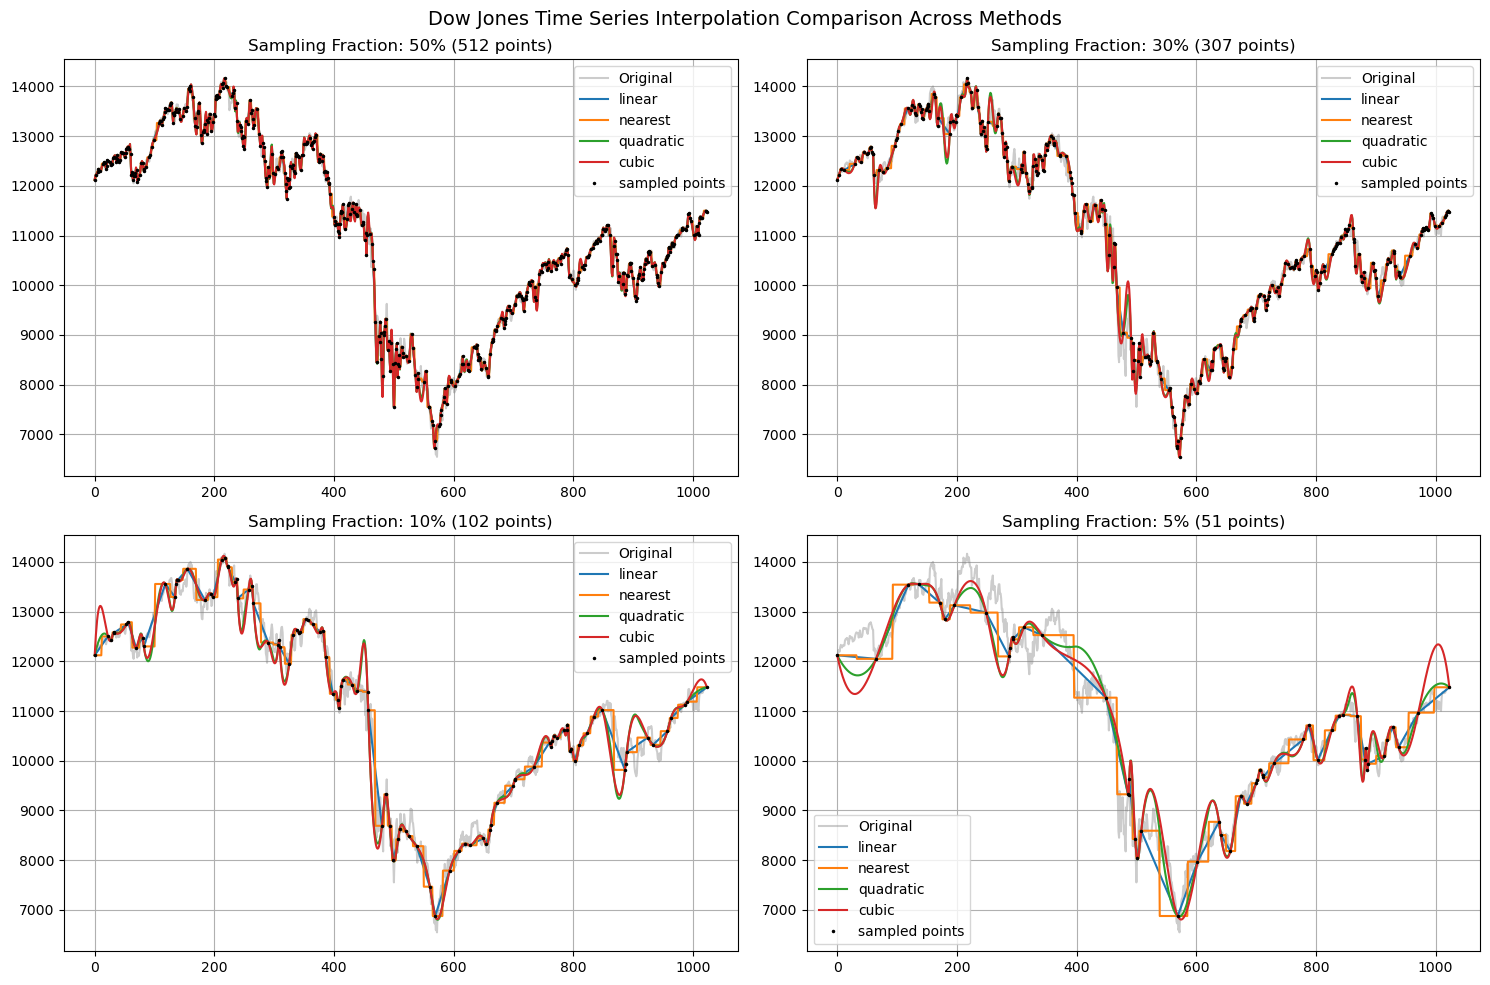

In [37]:
# Load time series dataset and extract series length
data = np.loadtxt("dow.txt")
n_pts = len(data)
x_full = np.arange(n_pts)
y_full = data

# Define sampling ratios and interpolation algorithms to compare
fractions = [0.50, 0.30, 0.10, 0.05]
methods = ['linear', 'nearest', 'quadratic', 'cubic']

plt.figure(figsize=(15, 10))

# Iterate through sampling fractions to evaluate reconstruction accuracy
for i, frac in enumerate(fractions):
    # Sample random indices and force inclusion of start and end domain boundaries
    num_samples = int(n_pts * frac)
    idx = np.sort(rng.choice(n_pts, size=num_samples, replace=False))
    idx[0], idx[-1] = 0, n_pts - 1

    # Extract sampled y-values once to avoid redundant array indexing
    y_sub = y_full[idx]

    plt.subplot(2, 2, i + 1)
    plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')

    # Fit interpolator using index values directly as x-coordinates
    for method in methods:
        f_interp = interpolate.interp1d(idx, y_sub, kind=method)
        plt.plot(x_full, f_interp(x_full), label=method)

    plt.plot(idx, y_sub, 'k.', markersize=3, label='sampled points')
    plt.title(f'Sampling Fraction: {int(frac * 100)}% ({num_samples} points)')
    plt.grid(True)
    plt.legend()

plt.suptitle('Dow Jones Time Series Interpolation Comparison Across Methods', fontsize=14)
plt.tight_layout()
plt.savefig("8-dowjones.png")
plt.show()

In [4]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

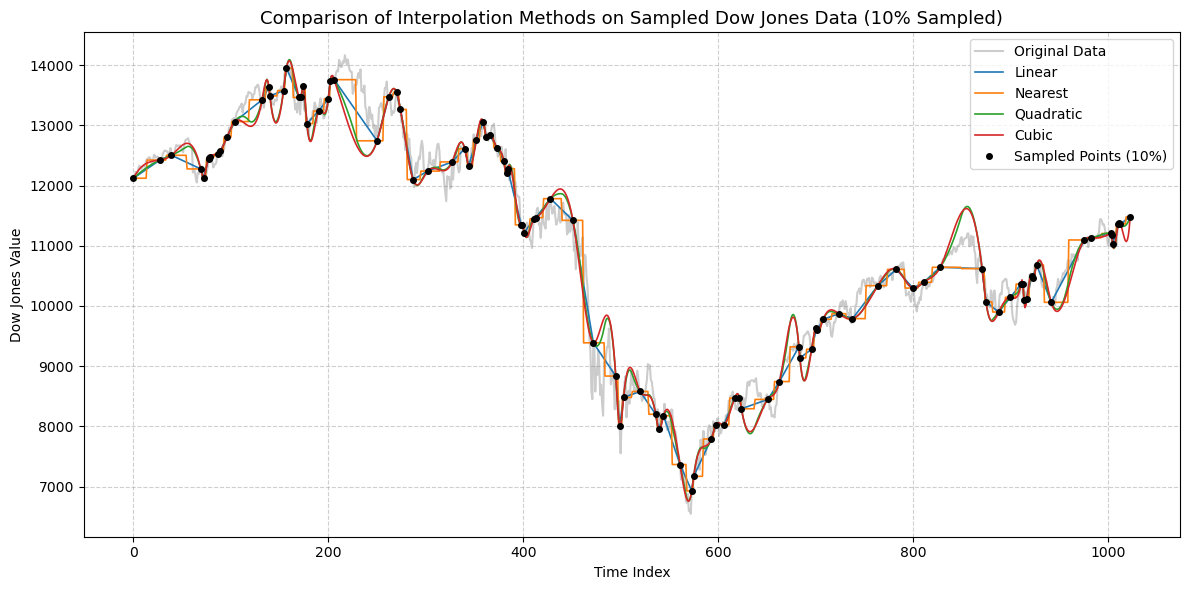

In [38]:
# Extract total dataset size and sample 10% random indices with forced boundary inclusion
sampled_idx = np.sort(rng.choice(len(data), size=int(len(data) * 0.10), replace=False))
sampled_idx[0], sampled_idx[-1] = 0, len(data) - 1

# Use sampled indices
x_sample, y_sample = x_full[sampled_idx], y_full[sampled_idx]

# Plot original data
plt.figure(figsize=(12, 6))
plt.plot(x_full, y_full, color='gray', alpha=0.4, linewidth=1.5, label='Original Data')

# loop over interpolation methods to create and plot each curve
for method in ['linear', 'nearest', 'quadratic', 'cubic']:
    f_interp = interpolate.interp1d(x_sample, y_sample, kind=method)
    plt.plot(x_full, f_interp(x_full), label=method.capitalize(), linewidth=1.2)

plt.plot(x_sample, y_sample, 'ko', markersize=4, label='Sampled Points (10%)')
plt.title('Comparison of Interpolation Methods on Sampled Dow Jones Data (10% Sampled)', fontsize=13)
plt.xlabel('Time Index')
plt.ylabel('Dow Jones Value')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("8-singlesampling.png")
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* This code compares four interpolation methods (linear, nearest, quadratic, and cubic) using SciPy's interpolate module by reconstructing a sine wave and Dow Jones stock data from random samples. It loops through SciPy's interp1d function to fit each method across different sampling rates. It also explicitly locks boundary endpoints to avoid out-of-bounds extrapolation errors and uses direct index sampling for efficiency.

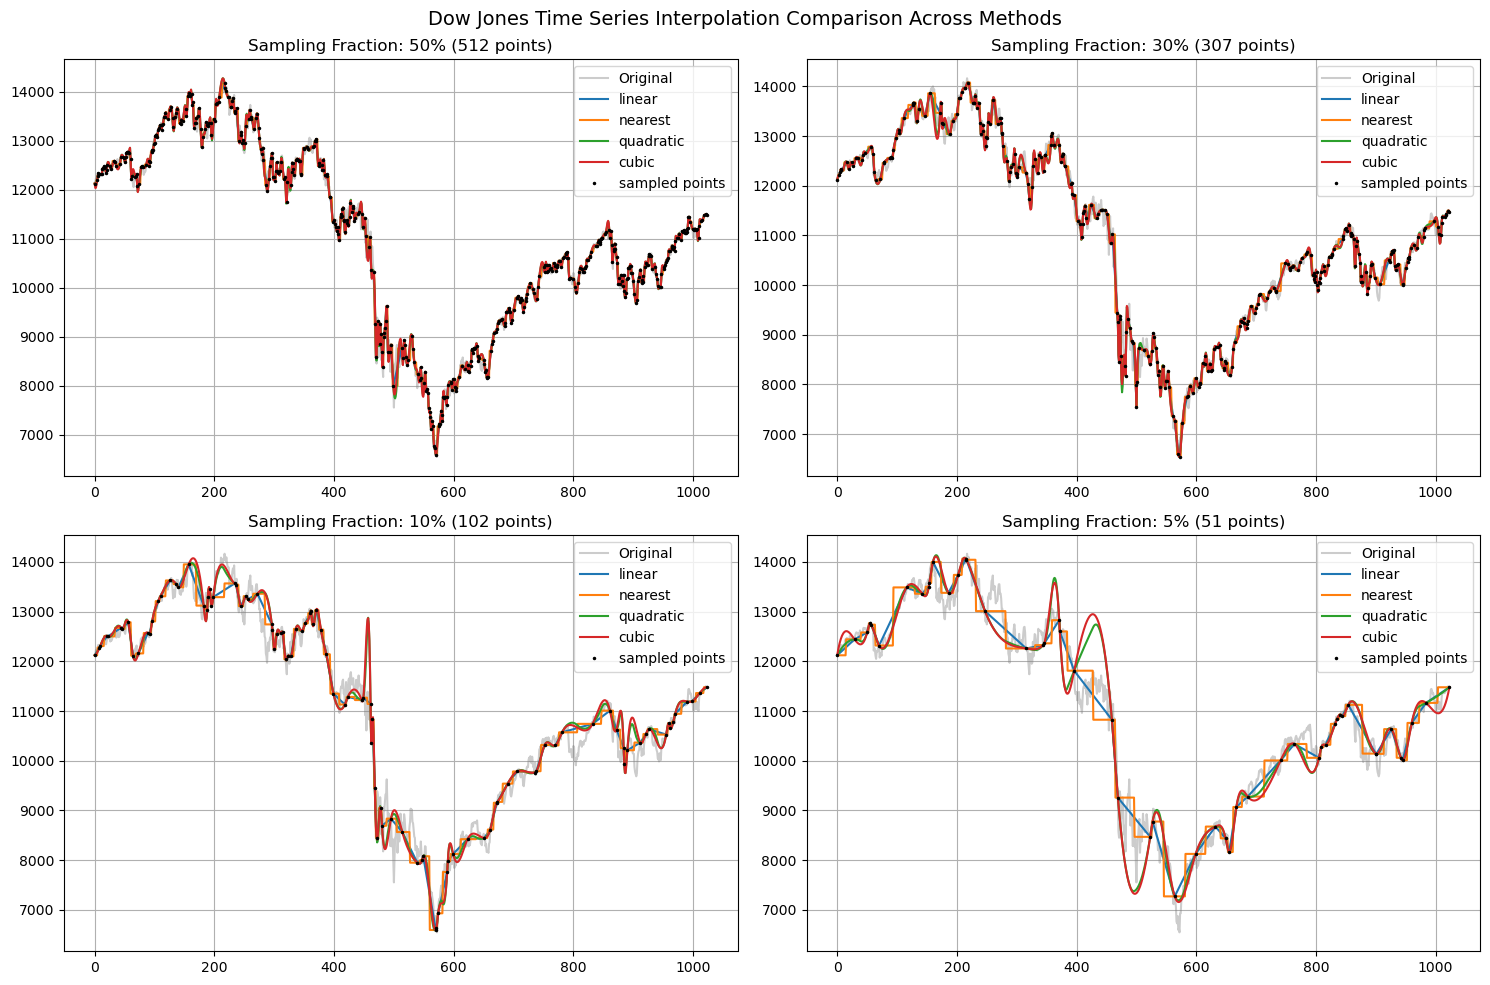

In [3]:
data = np.loadtxt("dow.txt")
x_full = np.arange(len(data))
y_full = data

idx_50 = np.sort(rng.choice(len(data), size=int(len(data) * 0.50), replace=False))
idx_50[0], idx_50[-1] = 0, len(data) - 1

idx_30 = np.sort(rng.choice(len(data), size=int(len(data) * 0.30), replace=False))
idx_30[0], idx_30[-1] = 0, len(data) - 1

idx_10 = np.sort(rng.choice(len(data), size=int(len(data) * 0.10), replace=False))
idx_10[0], idx_10[-1] = 0, len(data) - 1

idx_05 = np.sort(rng.choice(len(data), size=int(len(data) * 0.05), replace=False))
idx_05[0], idx_05[-1] = 0, len(data) - 1

f_50_linear    = interpolate.interp1d(x_full[idx_50], y_full[idx_50], kind='linear')
f_50_nearest   = interpolate.interp1d(x_full[idx_50], y_full[idx_50], kind='nearest')
f_50_quadratic = interpolate.interp1d(x_full[idx_50], y_full[idx_50], kind='quadratic')
f_50_cubic     = interpolate.interp1d(x_full[idx_50], y_full[idx_50], kind='cubic')

f_30_linear    = interpolate.interp1d(x_full[idx_30], y_full[idx_30], kind='linear')
f_30_nearest   = interpolate.interp1d(x_full[idx_30], y_full[idx_30], kind='nearest')
f_30_quadratic = interpolate.interp1d(x_full[idx_30], y_full[idx_30], kind='quadratic')
f_30_cubic     = interpolate.interp1d(x_full[idx_30], y_full[idx_30], kind='cubic')

f_10_linear    = interpolate.interp1d(x_full[idx_10], y_full[idx_10], kind='linear')
f_10_nearest   = interpolate.interp1d(x_full[idx_10], y_full[idx_10], kind='nearest')
f_10_quadratic = interpolate.interp1d(x_full[idx_10], y_full[idx_10], kind='quadratic')
f_10_cubic     = interpolate.interp1d(x_full[idx_10], y_full[idx_10], kind='cubic')

f_05_linear    = interpolate.interp1d(x_full[idx_05], y_full[idx_05], kind='linear')
f_05_nearest   = interpolate.interp1d(x_full[idx_05], y_full[idx_05], kind='nearest')
f_05_quadratic = interpolate.interp1d(x_full[idx_05], y_full[idx_05], kind='quadratic')
f_05_cubic     = interpolate.interp1d(x_full[idx_05], y_full[idx_05], kind='cubic')

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')
plt.plot(x_full, f_50_linear(x_full), label='linear')
plt.plot(x_full, f_50_nearest(x_full), label='nearest')
plt.plot(x_full, f_50_quadratic(x_full), label='quadratic')
plt.plot(x_full, f_50_cubic(x_full), label='cubic')
plt.plot(x_full[idx_50], y_full[idx_50], 'k.', markersize=3, label='sampled points')
plt.title(f'Sampling Fraction: 50% ({len(idx_50)} points)')
plt.grid(True)
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')
plt.plot(x_full, f_30_linear(x_full), label='linear')
plt.plot(x_full, f_30_nearest(x_full), label='nearest')
plt.plot(x_full, f_30_quadratic(x_full), label='quadratic')
plt.plot(x_full, f_30_cubic(x_full), label='cubic')
plt.plot(x_full[idx_30], y_full[idx_30], 'k.', markersize=3, label='sampled points')
plt.title(f'Sampling Fraction: 30% ({len(idx_30)} points)')
plt.grid(True)
plt.legend()


plt.subplot(2, 2, 3)
plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')
plt.plot(x_full, f_10_linear(x_full), label='linear')
plt.plot(x_full, f_10_nearest(x_full), label='nearest')
plt.plot(x_full, f_10_quadratic(x_full), label='quadratic')
plt.plot(x_full, f_10_cubic(x_full), label='cubic')
plt.plot(x_full[idx_10], y_full[idx_10], 'k.', markersize=3, label='sampled points')
plt.title(f'Sampling Fraction: 10% ({len(idx_10)} points)')
plt.grid(True)
plt.legend()


plt.subplot(2, 2, 4)
plt.plot(x_full, y_full, color='gray', alpha=0.4, label='Original')
plt.plot(x_full, f_05_linear(x_full), label='linear')
plt.plot(x_full, f_05_nearest(x_full), label='nearest')
plt.plot(x_full, f_05_quadratic(x_full), label='quadratic')
plt.plot(x_full, f_05_cubic(x_full), label='cubic')
plt.plot(x_full[idx_05], y_full[idx_05], 'k.', markersize=3, label='sampled points')
plt.title(f'Sampling Fraction: 5% ({len(idx_05)} points)')
plt.grid(True)
plt.legend()

plt.suptitle('Dow Jones Time Series Interpolation Comparison Across Methods', fontsize=14)
plt.tight_layout()
plt.show()